In [ ]:
# A bunch of code to clean up the raw data and fix the mislabeld items.

#Install and import libraries

# Install packages if you need them
#%pip install pandas
#%pip install seaborn
#%pip install scipy

# Import packages
import pandas as pd
import seaborn as sns
import pingouin as pg
import numpy as np

# Read in the data from the url
url = 'https://raw.githubusercontent.com/ethanweed/ExPsyLing/refs/heads/master/experiments/masked_prime/data/combined_data.csv'
raw = pd.read_csv(url)                                                      # read in the data from the url

# Make a list of all the columns we want to keep
cols = ['participant_id', 'sender', 'duration', 'prime', 'target', 'condition', 'soa_condition', 'congruence', 'response', 'correct_response']

# Filter the data to keep only the columns we want, and only the rows we want
df = raw[cols]                                                             # make a new dataframe with only the columns in cols
df = df[df['sender'] == 'target']                                          # only keep the "target" rows
df = df[df['condition'] != 'practice']                                     # throw away the practice trials

# Some of the target words were labeled incorrectly in the original data, so we need to fix those.
incorrect_labels = ['LAND', 'TREE', 'BEAR', 'ROSE', 'HILL', 'DIRT', 'BULL', 'DUCK']
for word in incorrect_labels:
    df.loc[df['target'] == word, 'correct_response'] = 'n'                 # fix items with incorrect answer lables

df['correct'] = (df['response'] == df['correct_response']).astype(int)     # make a new column with 0 or 1 for incorrect / correct
df = df[df['correct'] == 1]                                                # keep only the correct responses   
df = df.rename(columns={'soa_condition': 'soa', 'duration': 'rt'})         # rename the soa and duration columns, just to look nicer

In [ ]:
# Inspect the data
df.head()

,participant_id,sender,rt,prime,target,condition,soa,congruence,response,correct_response,correct
40,51,target,520.14,roof,PIANO,Inc_Synth_Synth,long,incongruent,m,m,1
47,51,target,640.66,sheep,BULL,Inc_Nat_Nat,long,incongruent,n,n,1
54,51,target,597.74,fort,GOAT,Inc_Synth_Nat,long,incongruent,n,n,1
61,51,target,495.68,pear,PEAR,Con_Nat,long,congruent,n,n,1
68,51,target,556.86,olive,MOTOR,Inc_Nat_Synth,long,incongruent,m,m,1


In [ ]:
# Calculate the mean RT for each participant in each congruence condition
data = df.groupby(['participant_id', 'congruence']).agg({'rt': 'mean'}).reset_index()

# Pivot the data to make it wide format, with one row per participant and one column per congruence condition
data_wide = data.pivot(index='participant_id', columns='congruence', values='rt').reset_index()
data_wide.head()

congruence,participant_id,congruent,incongruent
0,51,583.810000,615.085714
1,52,720.660000,770.758929
2,53,687.794545,715.216981
3,54,656.438182,745.021569
4,55,835.101852,757.564286


In [ ]:
# Calculate the difference score for each participant (congruent - incongruent)
data_wide['D'] = data_wide['congruent'] - data_wide['incongruent']
data_wide.head(20)

congruence,participant_id,congruent,incongruent,D
0,51,583.810000,615.085714,-31.275714
1,52,720.660000,770.758929,-50.098929
2,53,687.794545,715.216981,-27.422436
3,54,656.438182,745.021569,-88.583387
4,55,835.101852,757.564286,77.537566
5,56,555.301852,602.697826,-47.395974
6,57,670.320000,753.068519,-82.748518
7,58,751.071429,836.826923,-85.755495
8,59,749.790909,703.354386,46.436523
9,60,577.580702,608.235088,-30.654386


Text(0.5, 0, 'RT (ms)')

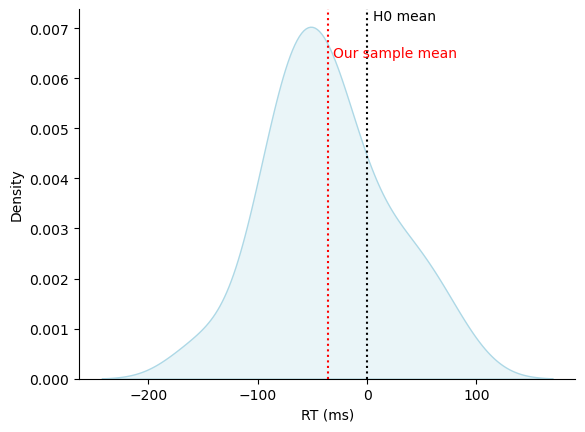

In [ ]:
## Plot the distribution of difference scores
ax = sns.kdeplot(data_wide['D'], fill=True, color='lightblue')                              # plot the distribution of difference scores
sns.despine()                                                                               # I was trained to prefer this 30 years ago. Can't help it.
ax.axvline(0, color='black', linestyle=':', linewidth=1.5)                                  # Draw a dotted line at 0 (the null hypothesis)
ax.axvline(data_wide['D'].mean(), color='red', linestyle=':', linewidth=1.5)                # Draw a dotted line at the mean of the difference scores
ax.text(0+5, 1, "H0 mean", transform=ax.get_xaxis_transform(),      
    color="black", ha="left", va="top")                                                     # Draw a label for the null hypothesis mean
ax.text(data_wide['D'].mean()+5, .9, "Our sample mean", transform=ax.get_xaxis_transform(),
    color="red", ha="left", va="top")                                                       # Draw a label for the sample mean
ax.set_xlabel('RT (ms)');                                                                   # Make a more sensible x-axis label

In [7]:
pg.ttest(data_wide['congruent'], data_wide['incongruent'], paired=True)

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,-2.844799,18,two-sided,0.010751,"[-62.8, -9.44]",0.354374,4.898,0.309804


Mean of simulated t-values: -0.005
Proportion with |t| > 2.10: 0.051 (should be about 0.05)


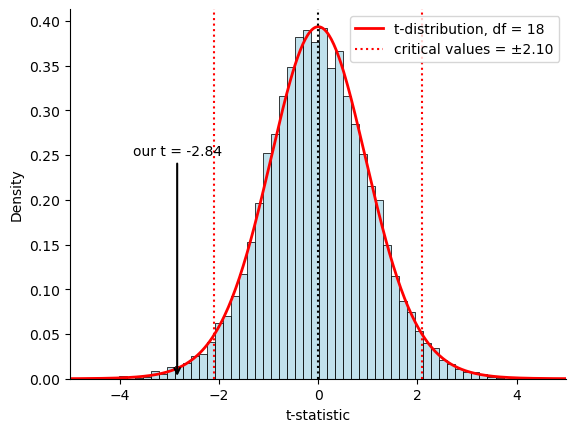

In [8]:
# SIMULATION: What do t-statistics look like when the null hypothesis (H0) is true?
#
# The idea: imagine a world where masked priming has NO effect, so the true mean
# difference between congruent and incongruent RTs is exactly 0.
# In that world, we "run our experiment" thousands of times, and each time we
# compute a t-statistic. Then we look at the distribution of all those t-values.

from scipy import stats   # we only need scipy for the theoretical t-distribution

# Settings for the simulation
# We copy the sample size and spread from our real data, so the simulated experiments
# look like ours in every way, except that the true effect is 0.
N = len(data_wide['D'])        # number of participants in our experiment
sd = data_wide['D'].std()      # standard deviation of our difference scores
n_experiments = 10000          # how many times we "repeat" the experiment

# A random number generator. We set a "seed" so that the results are reproducible.
# We choose 42 for the seed, because we are dorks.
rng = np.random.default_rng(42)

# Run the simulated experiments, and calculate a t-value for each one. Store the t-values in a list.
t_values = []                  # an empty list to collect one t-value per experiment
for i in range(n_experiments):
    # Draw N fake difference scores from a normal distribution centered on 0 (we are assuming H0 is true)
    sim_D = rng.normal(loc=0, scale=sd, size=N)

    # Compute the one-sample t-statistic by hand: t = mean / standard error.
    # (pg.ttest(sim_D, 0) would give the same answer, but it is much slower
    #  when we call it 10,000 times, so we do the arithmetic ourselves.)
    t = sim_D.mean() / (sim_D.std(ddof=1) / np.sqrt(N)) # (ddof=1 gives the sample standard deviation, not the population standard deviation)

    t_values.append(t)         # store this experiment's t-value

# Get our actual t-statistic from the real data, using the same paired t-test we ran above.
t_obs = pg.ttest(data_wide['congruent'], data_wide['incongruent'], paired=True)['T'].iloc[0]

# Critical values
# With alpha = 0.05 (two-tailed), 2.5% of the t-distribution lies in each tail.
# stats.t.ppf finds the t-value that has 97.5% of the distribution below it.
t_crit = stats.t.ppf(0.975, df=N-1)

# Plot the simulated t-values, the theoretical t-distribution under H0, the critical values, and our actual t-statistic.
# Histogram of the 10,000 simulated t-values.
# stat='density' scales the bars so they are comparable with the curve below.
ax = sns.histplot(t_values, stat='density', bins=60, color='lightblue')

# The theoretical t-distribution with N - 1 degrees of freedom.
# stats.t.pdf gives the height of the curve at each x-value.
x = np.linspace(-10, 10, 800)
sns.lineplot(x=x, y=stats.t.pdf(x, df=N-1), color='red', linewidth=2,
             label=f't-distribution, df = {N-1}', ax=ax)

# A dotted line at 0, where the t-values should be centered if H0 is true.
ax.axvline(0, color='black', linestyle=':', linewidth=1.5)

# Dotted red lines at the critical values. A t-value outside these lines
# would be "significant" at p < .05.
ax.axvline(-t_crit, color='red', linestyle=':', linewidth=1.5)
ax.axvline(t_crit, color='red', linestyle=':', linewidth=1.5,
           label=f'critical values = ±{t_crit:.2f}')

# Make an arrow pointing at where our actual t-statistic from our data falls.
ax.annotate(f'our t = {t_obs:.2f}',
            xy=(t_obs, 0),          # where the arrow points (on the x-axis)
            xytext=(t_obs, 0.25),   # where the label text sits
            ha='center',
            arrowprops=dict(arrowstyle='->', color='black', linewidth=1.5))

# Make sure the x-axis is wide enough to show our t-value, then tidy up.
ax.set_xlim(min(-5, t_obs - 1), max(5, t_obs + 1))
ax.set_xlabel('t-statistic')
ax.legend()
sns.despine()

# Check the simulation against the theory
# If H0 is true, the t-values should average about 0, and about 5% of them
# should fall beyond the critical values (that is what alpha = 0.05 means!).
print(f"Mean of simulated t-values: {np.mean(t_values):.3f}")
print(f"Proportion with |t| > {t_crit:.2f}: {np.mean(np.abs(t_values) > t_crit):.3f} (should be about 0.05)")
